### Environment & Enterprise KPI Dataset Generation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

np.random.seed(101)
n = 1200

regions = ['North America', 'Europe', 'Asia-Pacific', 'Latin America']
segments = ['Enterprise', 'Mid-Market', 'Small Business']
marketing_channels = ['Organic Search', 'Paid Ads', 'Email Campaigns', 'Referrals']

region_data = np.random.choice(regions, size=n, p=[0.35, 0.30, 0.25, 0.10])
segment_data = np.random.choice(segments, size=n, p=[0.25, 0.45, 0.30])
channel_data = np.random.choice(marketing_channels, size=n, p=[0.30, 0.25, 0.25, 0.20])

cac = np.random.gamma(shape=4, scale=120, size=n).round(2)
clv = (cac * np.random.uniform(2.5, 6.0, size=n) + np.random.normal(500, 150, size=n)).round(2)
quarterly_revenue = (clv * 0.28 + np.random.normal(100, 40, size=n)).round(2)
nps = np.clip(np.random.normal(loc=42, scale=18, size=n).astype(int), -20, 100)
churn_flag = (np.random.rand(n) < (0.28 - (clv / 15000) * 0.2 + (cac / 2000) * 0.15)).astype(int)

df = pd.DataFrame({
    'Region': region_data,
    'Customer_Segment': segment_data,
    'Acquisition_Channel': channel_data,
    'Customer_Acquisition_Cost_USD': cac,
    'Customer_Lifetime_Value_USD': clv,
    'Quarterly_Revenue_USD': quarterly_revenue,
    'Net_Promoter_Score': nps,
    'Churned': churn_flag
})

# Feature Engineering: ROI Ratio (CLV / CAC)
df['ROI_Ratio'] = (df['Customer_Lifetime_Value_USD'] / df['Customer_Acquisition_Cost_USD']).round(2)

print("Dataset Overview (1,200 Observations):")
df.head()

Dataset Overview (1,200 Observations):


,Region,Customer_Segment,Acquisition_Channel,Customer_Acquisition_Cost_USD,Customer_Lifetime_Value_USD,Quarterly_Revenue_USD,Net_Promoter_Score,Churned,ROI_Ratio
0,Europe,Enterprise,Organic Search,324.39,2042.01,605.77,33,1,6.29
1,Europe,Small Business,Paid Ads,418.57,2753.75,819.01,21,1,6.58
2,North America,Mid-Market,Email Campaigns,676.40,3933.60,1184.60,50,0,5.82
3,North America,Mid-Market,Paid Ads,730.21,4370.51,1303.23,31,1,5.99
4,Asia-Pacific,Mid-Market,Referrals,82.92,1011.76,431.81,96,0,12.20


### Regional Cohort Aggregation & Schema Diagnostics

In [2]:
print("--- Schema Diagnostics ---")
print(df.info())

# Aggregate Regional Performance
reg_summary = df.groupby('Region').agg(
    Total_Customers=('Churned', 'count'),
    Total_Revenue=('Quarterly_Revenue_USD', 'sum'),
    Mean_CAC=('Customer_Acquisition_Cost_USD', 'mean'),
    Mean_CLV=('Customer_Lifetime_Value_USD', 'mean'),
    Average_ROI=('ROI_Ratio', 'mean'),
    Churn_Rate=('Churned', 'mean')
).round(2).reset_index()

reg_summary['Churn_Rate'] = (reg_summary['Churn_Rate'] * 100).round(2)

print("\n--- Regional KPI Summary Table ---")
print(reg_summary)

--- Schema Diagnostics ---
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Region                         1200 non-null   str    
 1   Customer_Segment               1200 non-null   str    
 2   Acquisition_Channel            1200 non-null   str    
 3   Customer_Acquisition_Cost_USD  1200 non-null   float64
 4   Customer_Lifetime_Value_USD    1200 non-null   float64
 5   Quarterly_Revenue_USD          1200 non-null   float64
 6   Net_Promoter_Score             1200 non-null   int64  
 7   Churned                        1200 non-null   int64  
 8   ROI_Ratio                      1200 non-null   float64
dtypes: float64(4), int64(2), str(3)
memory usage: 123.6 KB
None

--- Regional KPI Summary Table ---
          Region  Total_Customers  Total_Revenue  Mean_CAC  Mean_CLV  \
0   Asia-Pacific              300      240216

### Executive Visual Dashboard & Annotated Correlation Matrix

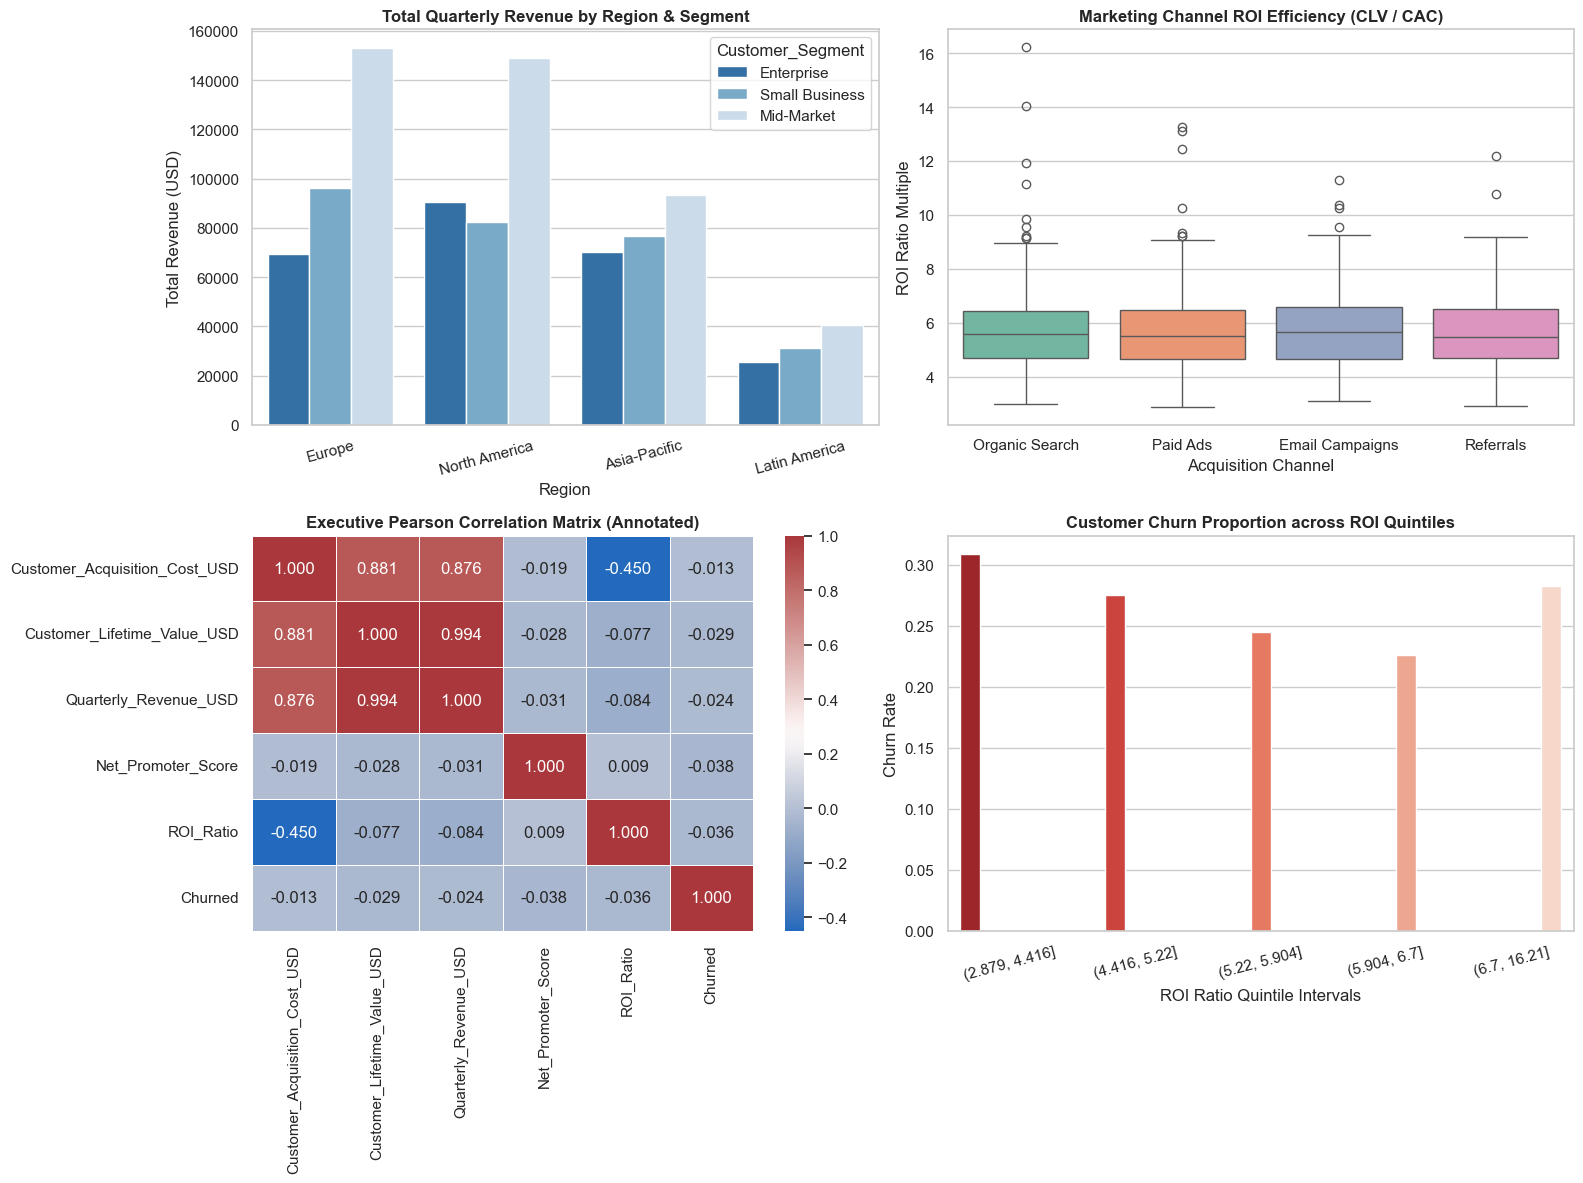


--- Exact Numerical Correlation Matrix ---
                               Customer_Acquisition_Cost_USD  \
Customer_Acquisition_Cost_USD                         1.0000   
Customer_Lifetime_Value_USD                           0.8809   
Quarterly_Revenue_USD                                 0.8760   
Net_Promoter_Score                                   -0.0189   
ROI_Ratio                                            -0.4500   
Churned                                              -0.0134   

                               Customer_Lifetime_Value_USD  \
Customer_Acquisition_Cost_USD                       0.8809   
Customer_Lifetime_Value_USD                         1.0000   
Quarterly_Revenue_USD                               0.9936   
Net_Promoter_Score                                 -0.0283   
ROI_Ratio                                          -0.0769   
Churned                                            -0.0295   

                               Quarterly_Revenue_USD  Net_Promoter_Score

In [4]:
numeric_cols = [
    'Customer_Acquisition_Cost_USD',
    'Customer_Lifetime_Value_USD',
    'Quarterly_Revenue_USD',
    'Net_Promoter_Score',
    'ROI_Ratio',
    'Churned'
]
corr_matrix = df[numeric_cols].corr().round(4)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Total Quarterly Revenue by Region & Segment
sns.barplot(
    data=df,
    x='Region',
    y='Quarterly_Revenue_USD',
    hue='Customer_Segment',
    estimator='sum',
    errorbar=None,
    palette='Blues_r',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Total Quarterly Revenue by Region & Segment', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Total Revenue (USD)')
axes[0, 0].tick_params(axis='x', rotation=15)

# 2. Marketing Channel ROI Efficiency
sns.boxplot(
    data=df,
    x='Acquisition_Channel',
    y='ROI_Ratio',
    hue='Acquisition_Channel',
    legend=False,
    palette='Set2',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Marketing Channel ROI Efficiency (CLV / CAC)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('ROI Ratio Multiple')
axes[0, 1].set_xlabel('Acquisition Channel')

# 3. Pearson Correlation Heatmap
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='vlag', ax=axes[1, 0], cbar=True, linewidths=0.5)
axes[1, 0].set_title('Executive Pearson Correlation Matrix (Annotated)', fontsize=12, fontweight='bold')

# 4. Customer Churn Proportion across ROI Quintiles
df['ROI_Decile'] = pd.qcut(df['ROI_Ratio'], q=5)
churn_decile = df.groupby('ROI_Decile', observed=True)['Churned'].mean().reset_index()
sns.barplot(
    data=churn_decile,
    x='ROI_Decile',
    y='Churned',
    hue='ROI_Decile',
    legend=False,
    palette='Reds_r',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Customer Churn Proportion across ROI Quintiles', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Churn Rate')
axes[1, 1].set_xlabel('ROI Ratio Quintile Intervals')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('task5_analytics_dashboard.png', dpi=300)
plt.show()

print("\n--- Exact Numerical Correlation Matrix ---")
print(corr_matrix)